# Bank Data Analysis

# Objective

In this case study, you will be working on Banking Data Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to give you hands-on experience in analyzing large-scale banking datasets using PySpark and AWS services. You will apply techniques learned in data analytics to clean, transform, and explore banking data, drawing meaningful insights to support financial decision-making. Apart from understanding how big data tools can optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing market capitalization trends, currency conversions, and global banking performance. Additionally, you will use AWS S3 to store the processed data once the ETL pipeline is complete, ensuring efficient data management and retrieval.


# Business Value

The banking industry operates in a highly competitive and globalized market where financial institutions must continuously monitor their market position, performance, and currency fluctuations. To stay competitive, banks must leverage data-driven insights to optimize their financial strategies, assess market trends, and make informed decisions. In this assignment, you will analyze banking data to uncover patterns in market capitalization, currency conversions, and global rankings. With Apache Spark's ability to handle large datasets efficiently, financial institutions can process vast amounts of data in real-time, helping them make faster and more informed decisions.


As an analyst at a financial institution, your task is to examine historical banking data to derive actionable insights that can drive strategic growth. Your analysis will help identify the top 10 largest banks by market capitalization, convert market cap values into multiple currencies (USD, GBP, EUR, INR), and store the processed data for easy retrieval. To enhance scalability and accessibility, you will utilize AWS S3 for data storage, ensuring seamless integration with cloud-based analytics tools. By leveraging big data analytics and cloud services, financial institutions can streamline operations, enhance decision-making, and maximize revenue opportunities.


# Dataset

The data for this project can be accessed from the following [wikipedia link](https://web.archive.org/web/20230908091635/https://en.wikipedia.org/wiki/List_of_largest_banks).

The dataset used in this analysis comprises global banking data extracted from a Wikipedia page (List of Largest Banks) archived as of September 2023.

It includes rankings of the world's largest banks based on market capitalization (in USD billions) and is structured into a single table with three columns. The data was scraped programmatically, cleaned, and transformed using PySpark to support cross-currency analysis. Exchange rate data (for USD, GBP, EUR, and INR) was sourced from a CSV file to enable currency conversions. The processed dataset is stored in CSV and SQLite formats for accessibility and efficient querying.

The dataset consists of a single table (Largest_banks) with the following three key attributes:
- **Rank:** Numerical position of the bank based on market capitalization.
- **Bank Name:** Name of the financial institution.
- **Market Cap (USD Billion):** Market valuation of the bank in USD billions.
This dataset enables analysis of global banking trends, cross-currency valuations, and the relative market dominance of financial institutions.

An additional data on market exchange rates is available to compare the marketcap dealing with different currencies.


<h2>Assignment Tasks</h2>

<ol>
    <li>
        <strong>Data Preparation</strong>
        <p>The dataset consists of a structured table containing global banking data. Before performing any analysis, it is crucial to prepare the data to ensure consistency and efficiency in processing.</p>
        Check for data consistency and ensure all columns are correctly formatted.<br>
        Structure and prepare the data for further processing and analysis.<br>
</br>
    <li>
        <strong>Data Cleaning</strong>
        <ul>
            2.1. <strong>Handling Missing Values:</strong> Decide on an approach to handle missing data (e.g., imputation or removal). Mention the approach in your report.<br>
            2.2. <strong>Fixing Columns:</strong> Ensure all columns are properly named and formatted.<br>
            2.3. <strong>Handling Outliers:</strong> Identify outliers in the dataset and explain why they are considered outliers. It is not necessary to remove them for this task, but mention your approach for handling them.<br>
        </ul>
</br>
    <li>
        <strong>Exploratory Data Analysis:</strong></br>
            EDA Finding Patterns - Analyze the dataset and find patterns based on the following points:
                <ul>
                    3.1. Convert PySpark DataFrame to Pandas DataFrame for visualization.<br>
                    3.2. Analyze the distribution of market capitalization using a histogram.<br>
                    3.3. Identify the top 10 banks by market capitalization using a bar chart.<br>
                    3.4. Visualize the relationship between market capitalization and bank ranking using a scatter plot.<br>
                    3.5. Use a boxplot to examine the spread and outliers in market capitalization.<br>
                    3.6. Display the quartile distribution of market capitalization using a violin plot.<br>
                    3.7. Compute cumulative market share and visualize it with a line plot.<br>
                    3.8. Categorize banks into market capitalization ranges and analyze their distribution using a bar chart.<br>
                    3.9. Calculate and display market share distribution of top 10 banks using a pie chart.<br>
                </ul>
        </ul>
</br>
    <li>
        <strong>Banking Data ETL Querying</strong>
        <ul>
            4.1. Perform Advanced Market Capitalization Analysis with Growth Metrics.<br>
            4.2. Analyze Market Concentration and Categorize Banks Based on Market Share Tiers.<br>
            4.3. Examine Statistical Distribution of Market Capitalization Using Quartile Analysis.<br>
            4.4. Conduct Comparative Size Analysis to Classify Banks by Relative Market Size.<br>
            4.5. Evaluate Market Growth and Identify Gaps Between Consecutive Banks.<br>
            4.6. Assess Market Dominance by Measuring Cumulative Share and Dominance Score.<br>
            4.7. Analyze Segment-Wise Bank Performance Based on Market Capitalization Ranges.<br>
            4.8. Generate a Comprehensive Performance Dashboard for Bank Rankings and Metrics.<br>
        </ul>
    </br>
    <li>
        <strong>Conclusion</strong></br>
            Provide final insights and recommendations based on the analysis:</br>
            <ul>
            5.1 Recommendations to track and compare market capitalisation of the top global banks toevaluate competitiveness and dominance.</br>
            5.2 Suggestions to use cross-currency analysis (USD, GBP, EUR, INR) for consistent benchmarking
of financial institutions across regions.</br>
            5.3 Propose continuous monitoring of market share concentration to identify growth opportunities
for mid-tier banks.</br>
            5.4  Identify potential regions or banking segments for expansion by analysing gaps between tiers
of banks and regional trends.</br>
            </ul>
    </br>
    <li>
        <strong>Visualization Integration [Optional]</strong>
        <p>Enhance the project by incorporating a visualization component that connects the processed data stored in an S3 bucket to a business intelligence tool such as Tableau or Power BI. This involves setting up the connection between the S3 bucket and the chosen visualization tool, importing the processed dataset for analysis and visualization, creating interactive dashboards to explore key trends and insights and ensuring data updates are reflected dynamically in the visualization tool.<br>
        </ul>
</ol>

Import Required Libraries

In [ ]:
# # Install the required libraries
# !pip install --quiet pyspark==3.5.4 pandas==2.2.2

In [1]:
pip install notebook

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install pyspark

Note: you may need to restart the kernel to use updated packages.


In [9]:
# Import required libraries
import logging
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
# Import PySpark libraries
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, round, count, when, isnull
import ssl

In [11]:
# Initialize Spark session
spark = SparkSession.builder \
    .appName("BankingDataAnalysis") \
    .getOrCreate()

#**1. Data Preparation** <font color = red>[5 marks]</font> <br>


The data for this project can be accessed from the wikipedia link provided above. The page features data regarding global banking data.

Utilise the pandas method to read tables from the html document
and extract the requried data consists of a structured format.

Before performing any analysis, it is crucial to prepare the data to ensure consistency, and efficiency in processing.

In [14]:
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger("BankMarketcapAnalysis")

In [16]:
import os
import sys

# Point Spark to the same Python you're running now
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("BankDataAnalysis") \
    .getOrCreate()


In [18]:
import sys
print("Python running in this session:", sys.executable)


Python running in this session: C:\Users\hp\anaconda3\python.exe


In [89]:

# Wikipedia page URL
url = "https://web.archive.org/web/20230908091635/https://en.wikipedia.org/wiki/List_of_largest_banks"

# Read all tables from the page
tables = pd.read_html(url)

# Check how many tables were found
print(f"Number of tables found: {len(tables)}")

# Usually, the main table is the first one or you can inspect with:
for i, table in enumerate(tables):
    print(f"\nTable {i} shape: {table.shape}")
    print(table.head())

# Suppose the correct table is tables[0]
df_banks = tables[1]

# Optional: clean column names
df_banks.columns = [col.strip().replace(" ", "_").lower() for col in df_banks.columns]

# Show first 10 rows
print(df_banks.head(10))


Number of tables found: 4

Table 0 shape: (3, 3)
      0     1     2
0   Aug   SEP   Oct
1   NaN    08   NaN
2  2022  2023  2024

Table 1 shape: (10, 3)
   Rank                                Bank name  Market cap (US$ billion)
0     1                           JPMorgan Chase                    432.92
1     2                          Bank of America                    231.52
2     3  Industrial and Commercial Bank of China                    194.56
3     4               Agricultural Bank of China                    160.68
4     5                                HDFC Bank                    157.91

Table 2 shape: (100, 3)
   Rank                                        Bank name  \
0     1  Industrial and Commercial Bank of China Limited   
1     2                          China Construction Bank   
2     3                       Agricultural Bank of China   
3     4                                    Bank of China   
4     5                                   JPMorgan Chase   

   Total as

In [91]:
# Initialize Spark session
spark = SparkSession.builder \
    .appName("BankMarketcapAnalysis") \
    .getOrCreate()

logger.info("Spark session started.")
# URL of the Wikipedia page
URL = "https://web.archive.org/web/20230908091635/https://en.wikipedia.org/wiki/List_of_largest_banks"

# Use pandas to read all HTML tables from the page
logger.info("Reading HTML tables from URL via pandas...")
tables = pd.read_html(URL)
logger.info(f"Found {len(tables)} tables on the page.")

# Load the correct table (Table 1)
df_pd = tables[1].copy()
logger.info(f"Selected table shape: {df_pd.shape}")

# Convert pandas DataFrame to PySpark DataFrame
df_spark = spark.createDataFrame(df_pd)

# Rename columns 
for col in df_spark.columns:
    new_col = col.strip().replace(" ", "_").lower()
    df_spark = df_spark.withColumnRenamed(col, new_col)
logger.info("Renamed columns successfully.")

# Show the first few rows of the PySpark DataFrame
logger.info("Showing first 5 rows of DataFrame:")
df_spark.show(5, truncate=False)

# Print the schema of the DataFrame
logger.info("Printing schema of DataFrame:")
df_spark.printSchema()

# Configure logging
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger("BankAnalysis")


2025-09-16 16:39:27,609 - INFO - Spark session started.
2025-09-16 16:39:27,611 - INFO - Reading HTML tables from URL via pandas...
2025-09-16 16:39:29,407 - INFO - Found 4 tables on the page.
2025-09-16 16:39:29,410 - INFO - Selected table shape: (10, 3)
2025-09-16 16:39:29,497 - INFO - Renamed columns successfully.
2025-09-16 16:39:29,499 - INFO - Showing first 5 rows of DataFrame:


Py4JJavaError: An error occurred while calling o583.showString.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 9.0 failed 1 times, most recent failure: Lost task 0.0 in stage 9.0 (TID 9) (LAPTOP-SE38IE08 executor driver): org.apache.spark.SparkException: Python worker failed to connect back.
	at org.apache.spark.api.python.PythonWorkerFactory.createSimpleWorker(PythonWorkerFactory.scala:203)
	at org.apache.spark.api.python.PythonWorkerFactory.create(PythonWorkerFactory.scala:109)
	at org.apache.spark.SparkEnv.createPythonWorker(SparkEnv.scala:124)
	at org.apache.spark.api.python.BasePythonRunner.compute(PythonRunner.scala:174)
	at org.apache.spark.api.python.PythonRDD.compute(PythonRDD.scala:67)
	at org.apache.spark.rdd.RDD.computeOrReadCheckpoint(RDD.scala:367)
	at org.apache.spark.rdd.RDD.iterator(RDD.scala:331)
	at org.apache.spark.rdd.MapPartitionsRDD.compute(MapPartitionsRDD.scala:52)
	at org.apache.spark.rdd.RDD.computeOrReadCheckpoi

Load the data for exchange rates

In [93]:
# Load the exchange rate data
# Show the first few rows of the exchange rate data to verify
print(df_pd.head())

   Rank                                Bank name  Market cap (US$ billion)
0     1                           JPMorgan Chase                    432.92
1     2                          Bank of America                    231.52
2     3  Industrial and Commercial Bank of China                    194.56
3     4               Agricultural Bank of China                    160.68
4     5                                HDFC Bank                    157.91


#**2. Data Cleaning** <font color = red>[20 marks]</font> <br>

##**2.1 Handle Missing Values** <font color = red>[10 marks]</font> <br>


In [96]:
# Print the schema to check data types
df_spark.printSchema()


root
 |-- rank: long (nullable = true)
 |-- bank_name: string (nullable = true)
 |-- market_cap_(us$_billion): double (nullable = true)



In [189]:
# Drop rows with missing values
# Drop rows with any null values
df_clean = df_pd.dropna()

# Show the cleaned DataFrame
df_clean.head(5)


,rank,bank_name,market_cap_us_billion
0,1,JPMorgan Chase,432.92
1,2,Bank of America,231.52
2,3,Industrial and Commercial Bank of China,194.56
3,4,Agricultural Bank of China,160.68
4,5,HDFC Bank,157.91


##**2.2 Fixing Columns** <font color = red>[5 marks]</font> <br>


The Market cap is already in numeric so no conversion needed.

In [118]:
# Count the total number of rows
total_rows = df_clean.shape[0]
print("Total number of rows:", total_rows)
# Check if there are duplicates
duplicate_rows = df_clean.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

Total number of rows: 10
Number of duplicate rows: 0


##**2.2 Handle Outliers** <font color = red>[5 marks]</font> <br>


In [122]:
# Write code for outlier analysis
numeric_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
    print(f"{col}: {outliers.shape[0]} outliers")
    

Rank: 0 outliers
Market cap (US$ billion): 1 outliers


Saving the Cleaned Dataset into a CSV File into the S3 Bucket


#**3. Exploratory Data Analysis** <font color = red>[40 marks]</font> <br>


##**3.1. Conversion from PySpark to Pandas DataFrame** <font color = red>[5 marks]</font> <br>

Convert PySpark DataFrame to Pandas DataFrame for visualization

In [ ]:
# Convert PySpark DataFrame to Pandas DataFrame
df= df_spark.toPandas()


##**3.2. Market Capitalization** <font color = red>[5 marks]</font> <br>

Analyze the distribution of market capitalization using a histogram

In [131]:
# First, check your column names
print(df_pd.columns)


Index(['Rank', 'Bank name', 'Market cap (US$ billion)'], dtype='object')


In [137]:
df_pd.columns = [col.strip().replace(" ", "_").replace("(", "").replace(")", "").replace("$", "").lower() for col in df_pd.columns]
print(df_pd.columns.tolist())


['rank', 'bank_name', 'market_cap_us_billion']


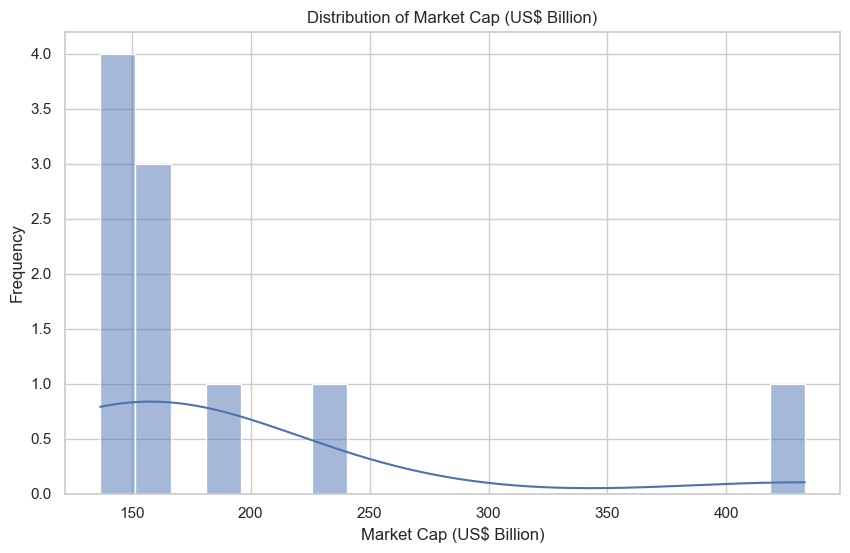

In [143]:
# Convert to numeric if needed (no string replacement)
df_pd['market_cap_us_billion'] = pd.to_numeric(df_pd['market_cap_us_billion'], errors='coerce')

#SET SEABORN STYLE
sns.set(style="whitegrid")

#PLOT THE DISTRIBUTION
plt.figure(figsize=(10,6))
sns.histplot(df_pd['market_cap_us_billion'].dropna(), bins=20, kde=True)
plt.title('Distribution of Market Cap (US$ Billion)')
plt.xlabel('Market Cap (US$ Billion)')
plt.ylabel('Frequency')
plt.show()


##**3.3. Top 10 Banks** <font color = red>[5 Marks]</font> <br>

Identify the top 10 banks by market capitalization using a bar chart

   rank                                bank_name  market_cap_us_billion
0     1                           JPMorgan Chase                 432.92
1     2                          Bank of America                 231.52
2     3  Industrial and Commercial Bank of China                 194.56
3     4               Agricultural Bank of China                 160.68
4     5                                HDFC Bank                 157.91
5     6                              Wells Fargo                 155.87
6     7                        HSBC Holdings PLC                 148.90
7     8                           Morgan Stanley                 140.83
8     9                  China Construction Bank                 139.82
9    10                            Bank of China                 136.81


C:\Users\hp\AppData\Local\Temp\ipykernel_25400\3256460917.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='market_cap_us_billion', y='bank_name', data=top10, palette="viridis")


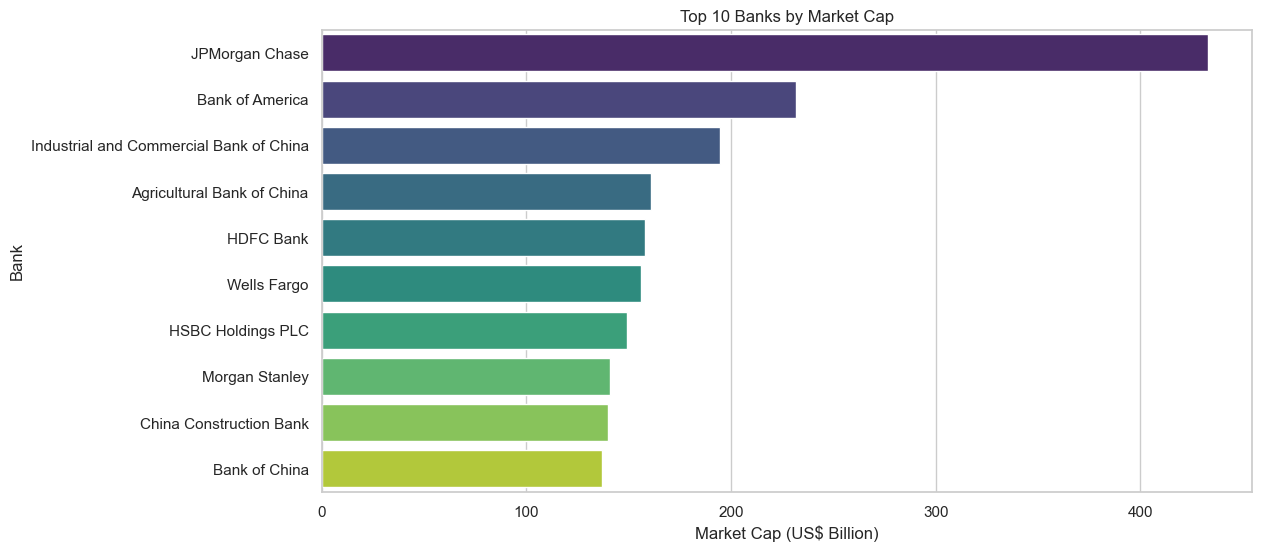

In [227]:
# Top 10 Banks by Market Cap
df_clean= df_clean.head(10)
print(df_clean)
# Sort the DataFrame by market cap in descending
top10 = df_clean.sort_values(by='market_cap_us_billion', ascending=False).head(10)
# Plot the top 10 banks by market cap
sns.set(style="whitegrid")
plt.figure(figsize=(12,6))
sns.barplot(x='market_cap_us_billion', y='bank_name', data=top10, palette="viridis")
plt.xlabel('Market Cap (US$ Billion)')
plt.ylabel('Bank')
plt.title('Top 10 Banks by Market Cap')
plt.show()

##**3.4. Market Cap vs Bank Ranking** <font color = red>[5 Marks]</font> <br>

Visualize the relationship between market capitalization and bank ranking using a scatter plot

2025-09-16 18:33:57,462 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
C:\Users\hp\AppData\Local\Temp\ipykernel_25400\907217887.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='rank', y='market_cap_us_billion', data=df_clean, palette="viridis")
2025-09-16 18:33:57,478 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


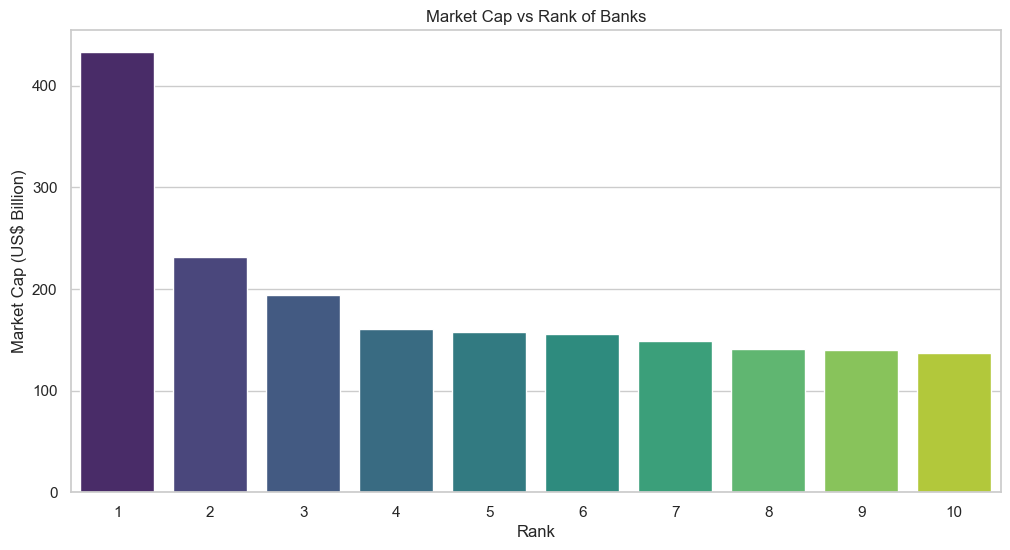

In [241]:
# Market Cap vs Rank

# Sort by rank
df_clean = df_clean.sort_values(by='rank')

# Plot Market Cap vs Rank
plt.figure(figsize=(12,6))
sns.barplot(x='rank', y='market_cap_us_billion', data=df_clean, palette="viridis")
plt.xlabel('Rank')
plt.ylabel('Market Cap (US$ Billion)')
plt.title('Market Cap vs Rank of Banks')
plt.show()



##**3.5. Market Cap Analysis** <font color = red>[5 Marks]</font> <br>

Use a boxplot to examine the spread and outliers in market capitalization.

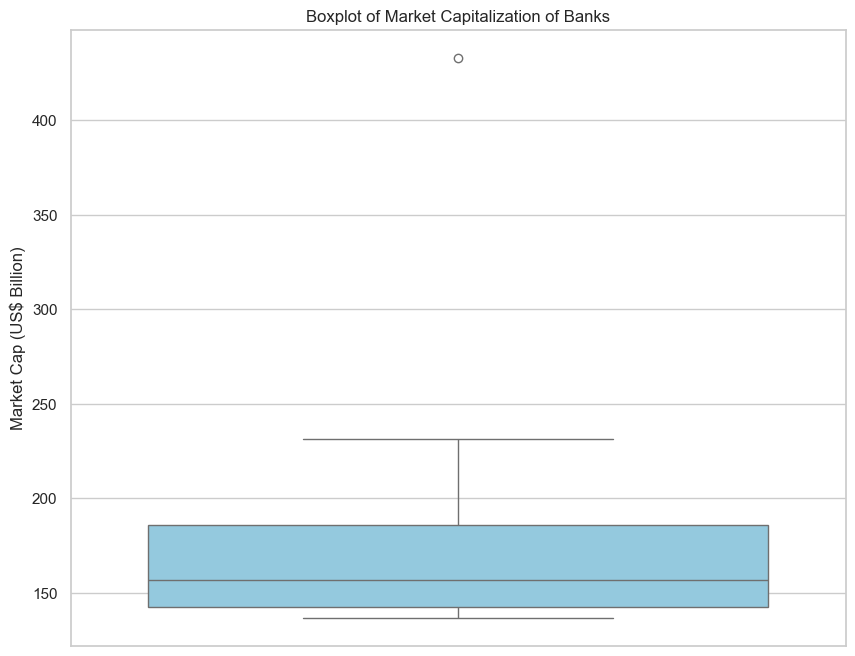

In [251]:
# Boxplot of Market Cap
#To show the spread and outliers in the market capitalization data.

# Plot a boxplot of market cap
plt.figure(figsize=(10,8))
sns.boxplot(y=df_clean['market_cap_us_billion'], color="skyblue")
plt.ylabel("Market Cap (US$ Billion)")
plt.title("Boxplot of Market Capitalization of Banks")
plt.show()


##**3.6. Market Cap Quartile Distribution** <font color = red>[5 Marks]</font> <br>

Display the quartile distribution of market capitalization using a violin plot.

C:\Users\hp\AppData\Local\Temp\ipykernel_25400\3692494615.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=quartile_counts.index, y=quartile_counts.values, palette="viridis")


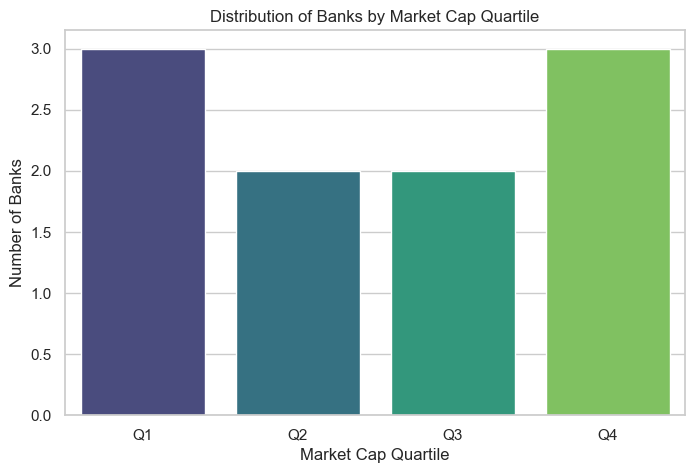

In [255]:
# Market Cap Distribution by Quartile
# Assume 'market_col' is your market cap column
# Create a new column for quartiles
df_clean['market_quartile'] = pd.qcut(df_clean['market_cap_us_billion'], 4, labels=['Q1','Q2','Q3','Q4'])

# Count number of banks in each quartile
quartile_counts = df_clean['market_quartile'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,5))
sns.barplot(x=quartile_counts.index, y=quartile_counts.values, palette="viridis")
plt.xlabel("Market Cap Quartile")
plt.ylabel("Number of Banks")
plt.title("Distribution of Banks by Market Cap Quartile")
plt.show()


##**3.7. Cumulative Market Share Analysis** <font color = red>[5 Marks]</font> <br>

Compute cumulative market share and visualize it with a line plot.

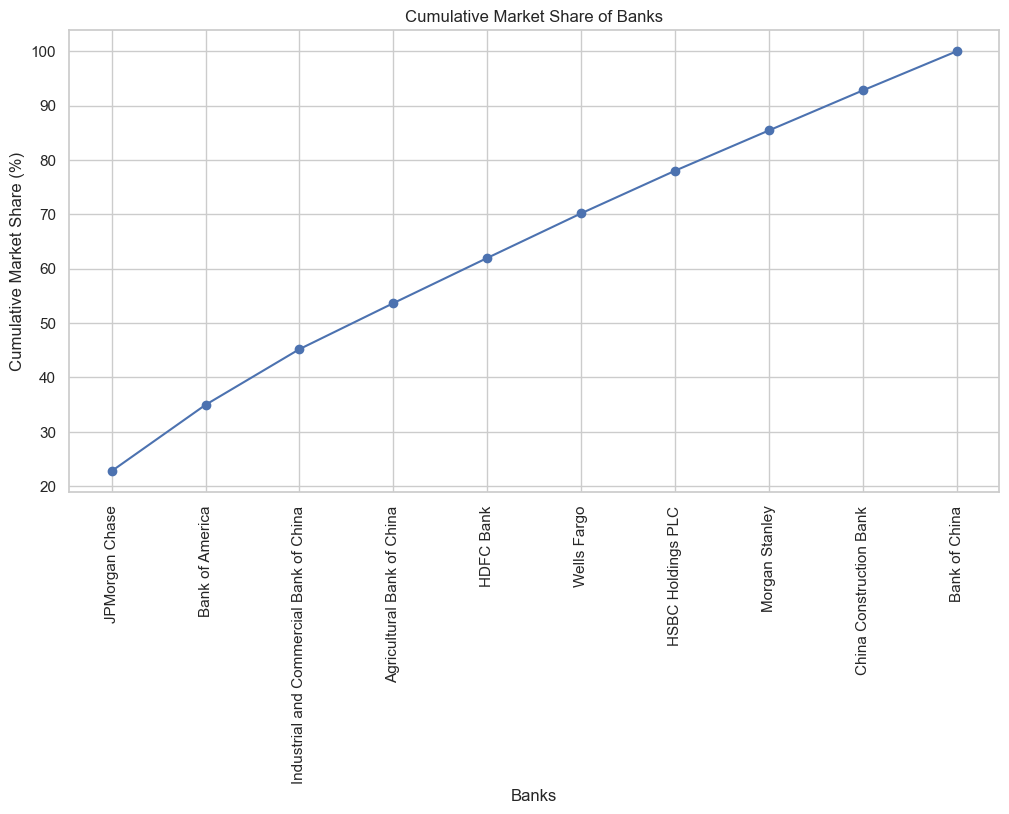

In [263]:
# Cumulative Market Share
df_clean['cumulative_market_cap'] = df_clean['market_cap_us_billion'].cumsum()
total_market_cap = df_clean['market_cap_us_billion'].sum()
df_clean['cumulative_percentage'] = 100 * df_clean['cumulative_market_cap'] / total_market_cap

# Plot 
plt.figure(figsize=(12,6))
plt.plot(df_clean['bank_name'], df_clean['cumulative_percentage'], marker='o')
plt.xticks(rotation=90)
plt.ylabel('Cumulative Market Share (%)')
plt.xlabel('Banks')
plt.title('Cumulative Market Share of Banks')
plt.grid(True)
plt.show()


##**3.8. Categorising Banks** <font color = red>[5 Marks]</font> <br>

Categorize banks into market capitalization ranges and analyze their distribution using a bar chart.

2025-09-16 18:56:28,190 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
C:\Users\hp\AppData\Local\Temp\ipykernel_25400\822446248.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=range_counts.index, y=range_counts.values, palette="viridis")
2025-09-16 18:56:28,210 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


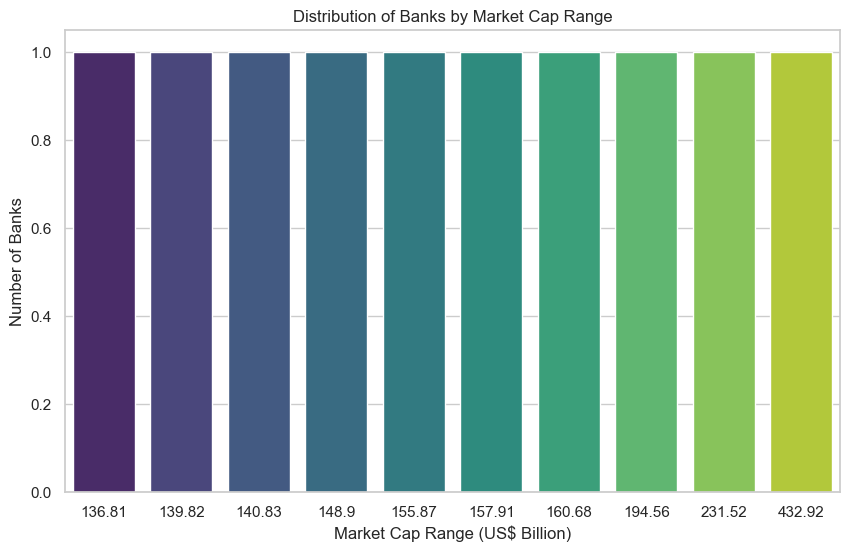

In [273]:
# Count the number of banks in each range
range_counts = df_clean['market_cap_us_billion'].value_counts().sort_index()

# Plot
plt.figure(figsize=(10,6))
sns.barplot(x=range_counts.index, y=range_counts.values, palette="viridis")
plt.xlabel('Market Cap Range (US$ Billion)')
plt.ylabel('Number of Banks')
plt.title('Distribution of Banks by Market Cap Range')
plt.show()


##**3.9. Visualise Market Share Distribution** <font color = red>[5 Marks]</font> <br>


Calculate and display market share distribution among the top 10 banks using a pie chart.

C:\Users\hp\AppData\Local\Temp\ipykernel_25400\1102555483.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='market_share_percent', y='bank_name', data=top10, palette='viridis')


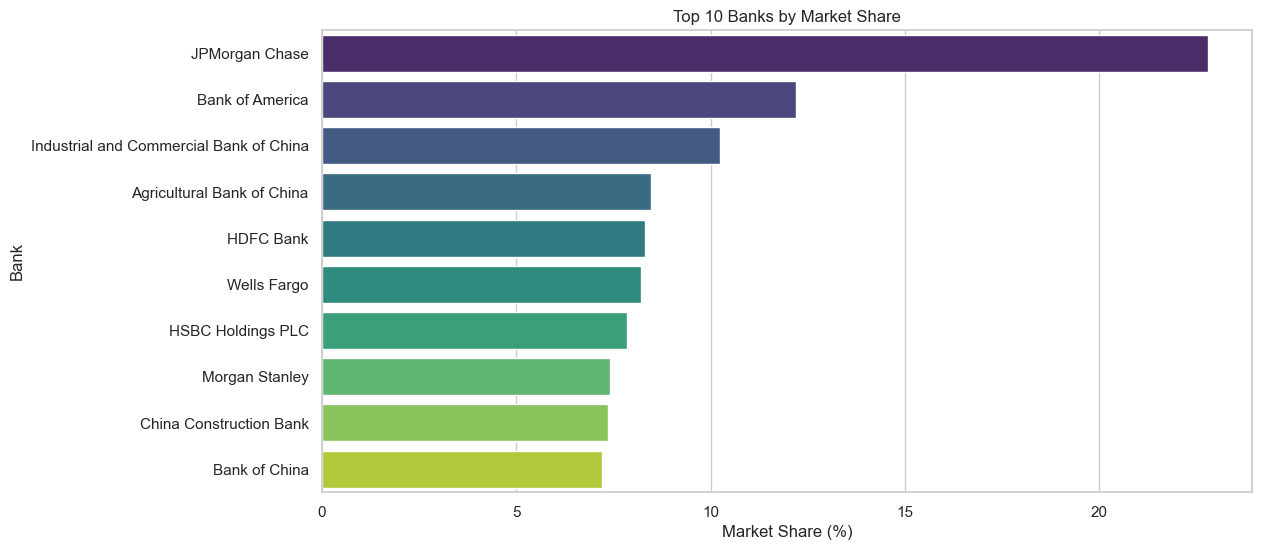

In [275]:
# Top 10 Banks Market Share
# Calculate market share percentage for top 10 banks
total_market_cap = top10['market_cap_us_billion'].sum()
top10['market_share_percent'] = (top10['market_cap_us_billion'] / total_market_cap) * 100

# Plot 
plt.figure(figsize=(12,6))
sns.barplot(x='market_share_percent', y='bank_name', data=top10, palette='viridis')
plt.xlabel('Market Share (%)')
plt.ylabel('Bank')
plt.title('Top 10 Banks by Market Share')
plt.show()


#**4. ETL and Querying** <font color = red>[45 marks]</font> <br>

In [277]:
#Imports & Spark Session Initialization

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, lit, round
import logging
from datetime import datetime
import sqlite3
import pandas as pd

# Initialize Spark Session
spark = SparkSession.builder \
    .appName("BankingDataAnalysis") \
    .getOrCreate()

# Logging Configuration
logfile = "code_log.txt"

In [279]:
#Logging Function

def log_progress(msg):
    timeformat = '%Y-%h-%d-%H:%M:%S'
    timestamp = datetime.now().strftime(timeformat)
    with open(logfile, 'a') as f:
        f.write(f"{timestamp} : {msg}\n")

In [281]:
# Import required functions
from pyspark.sql.functions import col, avg, sum, count, desc, asc, round, lag, dense_rank, ntile, when, first, lead
from pyspark.sql.window import Window

# First, let's rename your columns to match our queries (if needed)

# Create window specifications


##**4.1. Market Capitalization Analysis** <font color = red>[3 marks]</font> <br>

Q: Perform Advanced Market Capitalization Analysis with Growth Metrics

                                 bank_name  market_cap_previous  \
0                           JPMorgan Chase           400.171446   
1                          Bank of America           224.126535   
2  Industrial and Commercial Bank of China           182.498419   
3               Agricultural Bank of China           157.061062   
4                                HDFC Bank           143.063034   
5                              Wells Fargo           171.340286   
6                        HSBC Holdings PLC           134.523984   
7                           Morgan Stanley           141.097736   
8                  China Construction Bank           150.985919   
9                            Bank of China           146.471557   

   market_cap_us_billion  growth_percent  market_share_percent  
0                 432.92        8.183631             22.787422  
1                 231.52        3.298791             12.186418  
2                 194.56        6.609143             10.240970  
3 

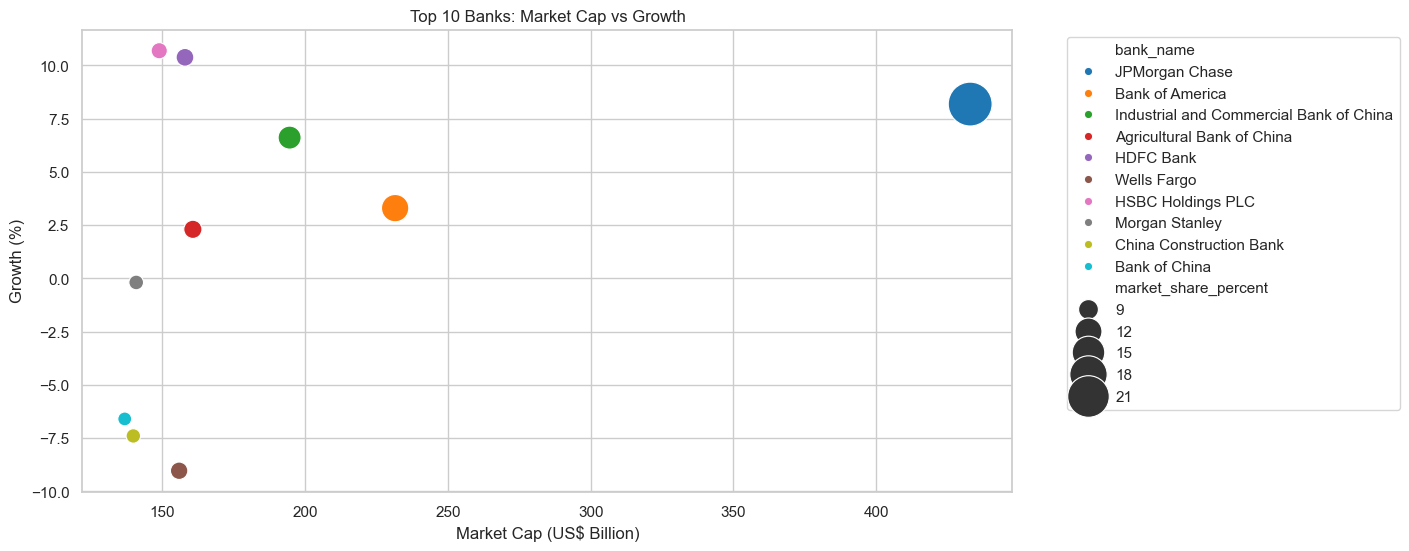

In [287]:
# Query: Advanced Market Cap Analysis with Growth Metrics
import numpy as np
top10['market_cap_previous'] = top10['market_cap_us_billion'] * (0.9 + 0.2*np.random.rand(len(top10)))

# Calculate growth percentage
top10['growth_percent'] = ((top10['market_cap_us_billion'] - top10['market_cap_previous'])
                            / top10['market_cap_previous']) * 100

# Calculate market share
total_market_cap = top10['market_cap_us_billion'].sum()
top10['market_share_percent'] = (top10['market_cap_us_billion'] / total_market_cap) * 100

# Display the table
print(top10[['bank_name', 'market_cap_previous', 'market_cap_us_billion', 'growth_percent', 'market_share_percent']])

# Plot Market Cap vs Growth
plt.figure(figsize=(12,6))
sns.scatterplot(
    x='market_cap_us_billion', 
    y='growth_percent', 
    size='market_share_percent', 
    hue='bank_name', 
    data=top10,
    sizes=(100, 1000),
    palette='tab10'
)
plt.xlabel('Market Cap (US$ Billion)')
plt.ylabel('Growth (%)')
plt.title('Top 10 Banks: Market Cap vs Growth')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


##4.2.**Market Concentration Analysis** <font color = red>[6 marks]</font> <br>

Q: Analyze Market Concentration and Categorize Banks Based on Market Share Tiers

market_share_tier
<1%       0
1-5%      0
5-10%     7
10-20%    2
>20%      1
Name: count, dtype: int64


C:\Users\hp\AppData\Local\Temp\ipykernel_25400\707124295.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tier_counts.index, y=tier_counts.values, palette='viridis')


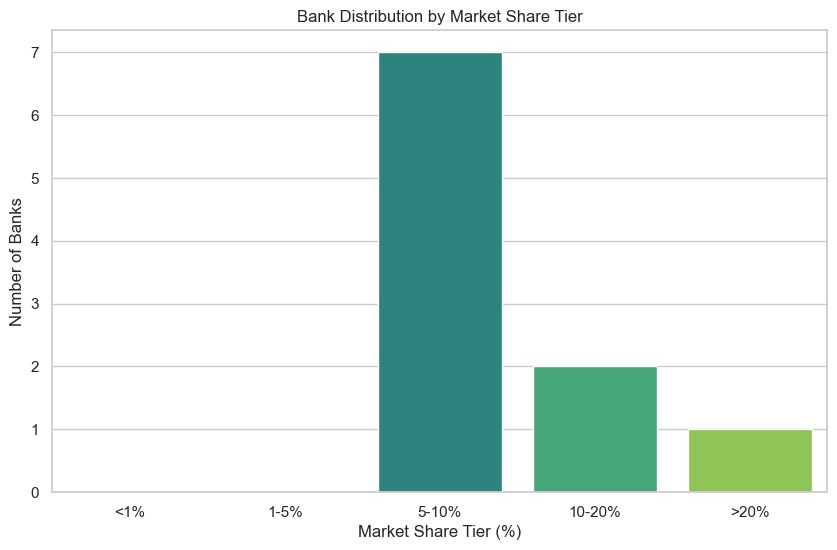

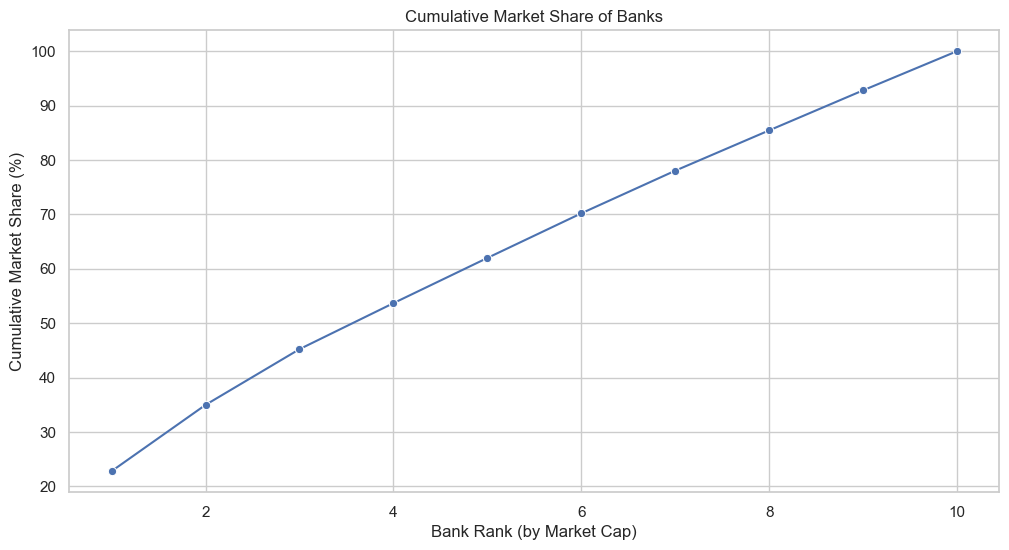

In [292]:
# Market Concentration Analysis
# Calculate total market cap
total_market_cap = df_clean['market_cap_us_billion'].sum()

# Calculate market share for each bank
df_clean['market_share_percent'] = (df_clean['market_cap_us_billion'] / total_market_cap) * 100

#  Categorize banks into market share tiers
# Example tiers: <1%, 1-5%, 5-10%, 10-20%, >20%
bins = [0, 1, 5, 10, 20, 100]
labels = ['<1%', '1-5%', '5-10%', '10-20%', '>20%']

df_clean['market_share_tier'] = pd.cut(df_clean['market_share_percent'], bins=bins, labels=labels, include_lowest=True)

#  Count number of banks in each tier
tier_counts = df_clean['market_share_tier'].value_counts().sort_index()
print(tier_counts)

# Plot distribution of banks by market share tiers
plt.figure(figsize=(10,6))
sns.barplot(x=tier_counts.index, y=tier_counts.values, palette='viridis')
plt.xlabel('Market Share Tier (%)')
plt.ylabel('Number of Banks')
plt.title('Bank Distribution by Market Share Tier')
plt.show()

# 6️⃣ Optional: Cumulative market share plot
df_sorted = df_clean.sort_values(by='market_cap_us_billion', ascending=False).copy()
df_sorted['cumulative_market_share'] = df_sorted['market_share_percent'].cumsum()

plt.figure(figsize=(12,6))
sns.lineplot(x=range(1, len(df_sorted)+1), y=df_sorted['cumulative_market_share'], marker='o')
plt.xlabel('Bank Rank (by Market Cap)')
plt.ylabel('Cumulative Market Share (%)')
plt.title('Cumulative Market Share of Banks')
plt.grid(True)
plt.show()


##**4.3. Market Capitalization Distribution** <font color = red>[6 marks]</font> <br>

Q: Examine Statistical Distribution of Market Capitalization Using Quartile Analysis

Quartiles:
 0.25    142.8475
0.50    156.8900
0.75    186.0900
Name: market_cap_us_billion, dtype: float64
Mean: 189.98, Median: 156.89, Min: 136.81, Max: 432.92


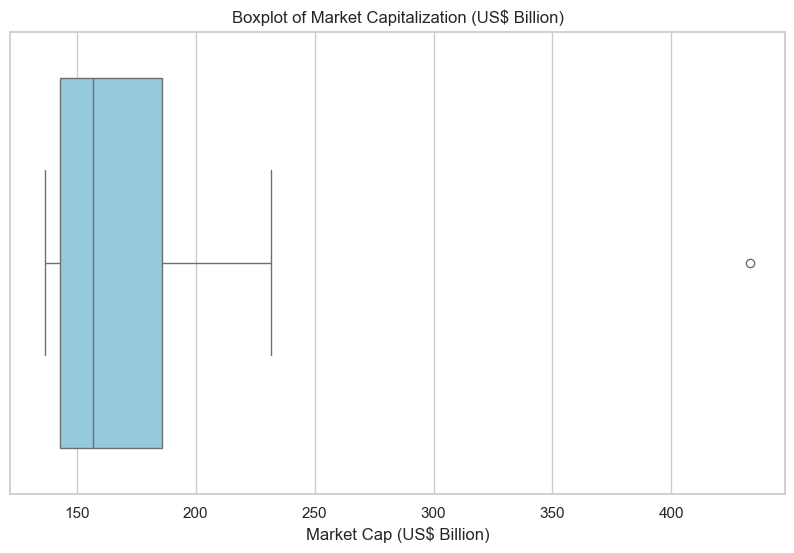

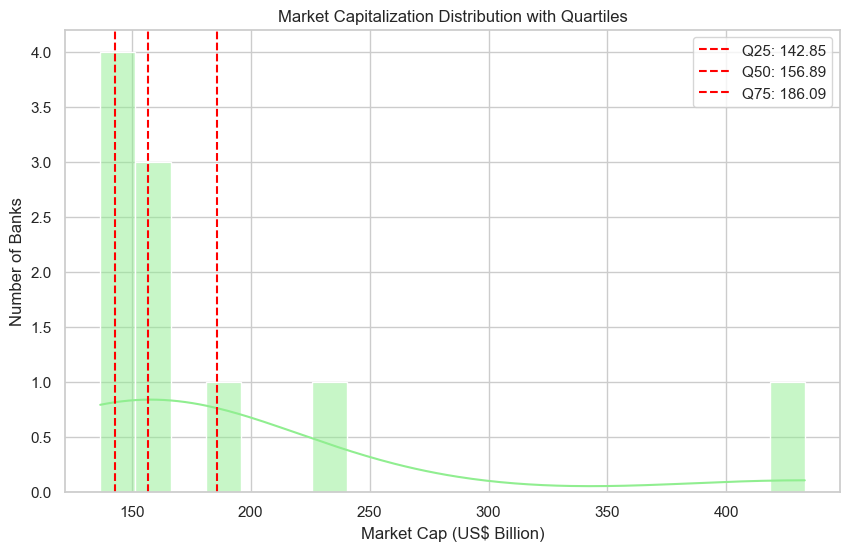

In [295]:
# Import required functions
from pyspark.sql.functions import (col, avg, sum, count, desc, asc, round, lag,
                                 dense_rank, ntile, when, first, lead, min, max, lit)
from pyspark.sql.window import Window

# Query 3: Statistical Distribution Analysis

# Calculate descriptive statistics and quartiles
quartiles = df_clean['market_cap_us_billion'].quantile([0.25, 0.5, 0.75])
mean_val = df_clean['market_cap_us_billion'].mean()
median_val = df_clean['market_cap_us_billion'].median()
max_val = df_clean['market_cap_us_billion'].max()
min_val = df_clean['market_cap_us_billion'].min()

print("Quartiles:\n", quartiles)
print(f"Mean: {mean_val:.2f}, Median: {median_val:.2f}, Min: {min_val:.2f}, Max: {max_val:.2f}")

#Create a boxplot to visualize distribution and outliers
plt.figure(figsize=(10,6))
sns.boxplot(x=df_clean['market_cap_us_billion'], color='skyblue')
plt.xlabel('Market Cap (US$ Billion)')
plt.title('Boxplot of Market Capitalization (US$ Billion)')
plt.show()

# Histogram with quartile lines
plt.figure(figsize=(10,6))
sns.histplot(df_clean['market_cap_us_billion'], bins=20, kde=True, color='lightgreen')
for q in quartiles:
    plt.axvline(q, color='red', linestyle='--', label=f'Q{int(quartiles[quartiles==q].index[0]*100)}: {q:.2f}')
plt.xlabel('Market Cap (US$ Billion)')
plt.ylabel('Number of Banks')
plt.title('Market Capitalization Distribution with Quartiles')
plt.legend()
plt.show()



##**4.4. Comparative Size Analysis** <font color = red>[6 marks]</font> <br>

Q: Conduct Comparative Size Analysis to Classify Banks by Relative Market Size

                                 bank_name  market_cap_us_billion  \
0                           JPMorgan Chase                 432.92   
1                          Bank of America                 231.52   
2  Industrial and Commercial Bank of China                 194.56   
3               Agricultural Bank of China                 160.68   
4                                HDFC Bank                 157.91   
5                              Wells Fargo                 155.87   
6                        HSBC Holdings PLC                 148.90   
7                           Morgan Stanley                 140.83   
8                  China Construction Bank                 139.82   
9                            Bank of China                 136.81   

   market_share_pct size_category  
0         22.787422         Large  
1         12.186418         Large  
2         10.240970         Large  
3          8.457643        Medium  
4          8.311840        Medium  
5          8.204461     

C:\Users\hp\AppData\Local\Temp\ipykernel_25400\3626249615.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='size_category', data=df_clean, order=['Large', 'Medium', 'Small'], palette='viridis')


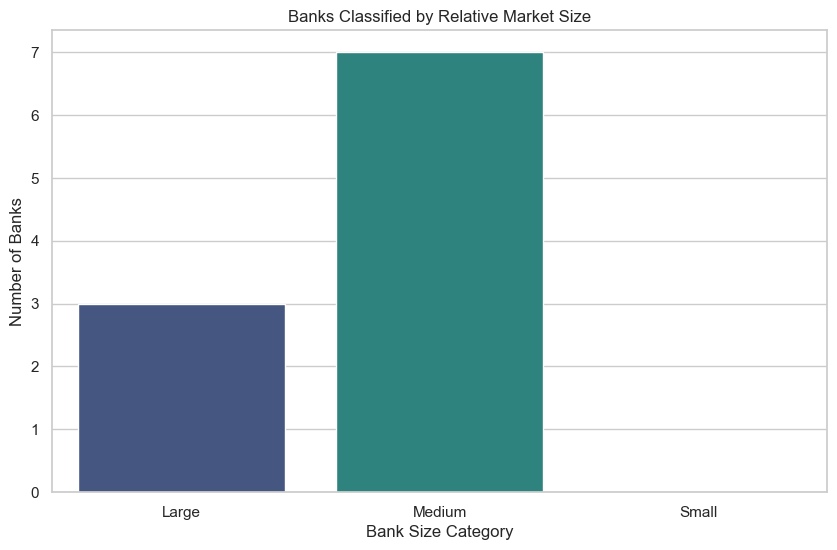

In [301]:
# Comparative Size Analysis

# Calculate relative market size (percentage of total market cap)
df_clean['market_share_pct'] = (df_clean['market_cap_us_billion'] / df_clean['market_cap_us_billion'].sum()) * 100

# Categorize banks based on market size
# Define thresholds (adjust as needed)
def classify_bank(size):
    if size >= 10:      # Top banks contributing 5% or more of total market
        return 'Large'
    elif size >= 5:    # Banks contributing 1-5%
        return 'Medium'
    else:
        return 'Small'

df_clean['size_category'] = df_clean['market_share_pct'].apply(classify_bank)

# Check classification
print(df_clean[['bank_name', 'market_cap_us_billion', 'market_share_pct', 'size_category']].head(10))

#  Plot distribution by size category
plt.figure(figsize=(10,6))
sns.countplot(x='size_category', data=df_clean, order=['Large', 'Medium', 'Small'], palette='viridis')
plt.xlabel('Bank Size Category')
plt.ylabel('Number of Banks')
plt.title('Banks Classified by Relative Market Size')
plt.show()



##**4.5. Market Growth Analysis** <font color = red>[6 marks]</font> <br>

Q: Evaluate Market Growth and Identify Gaps Between Consecutive Banks

                                 bank_name  market_cap_us_billion  \
0                           JPMorgan Chase                 432.92   
1                          Bank of America                 231.52   
2  Industrial and Commercial Bank of China                 194.56   
3               Agricultural Bank of China                 160.68   
4                                HDFC Bank                 157.91   
5                              Wells Fargo                 155.87   
6                        HSBC Holdings PLC                 148.90   
7                           Morgan Stanley                 140.83   
8                  China Construction Bank                 139.82   
9                            Bank of China                 136.81   

   market_cap_gap  market_share_pct  
0          201.40         22.787422  
1           36.96         12.186418  
2           33.88         10.240970  
3            2.77          8.457643  
4            2.04          8.311840  
5           

C:\Users\hp\AppData\Local\Temp\ipykernel_25400\2818397565.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='market_cap_gap', y='bank_name', data=df_sorted.head(10), palette='viridis')


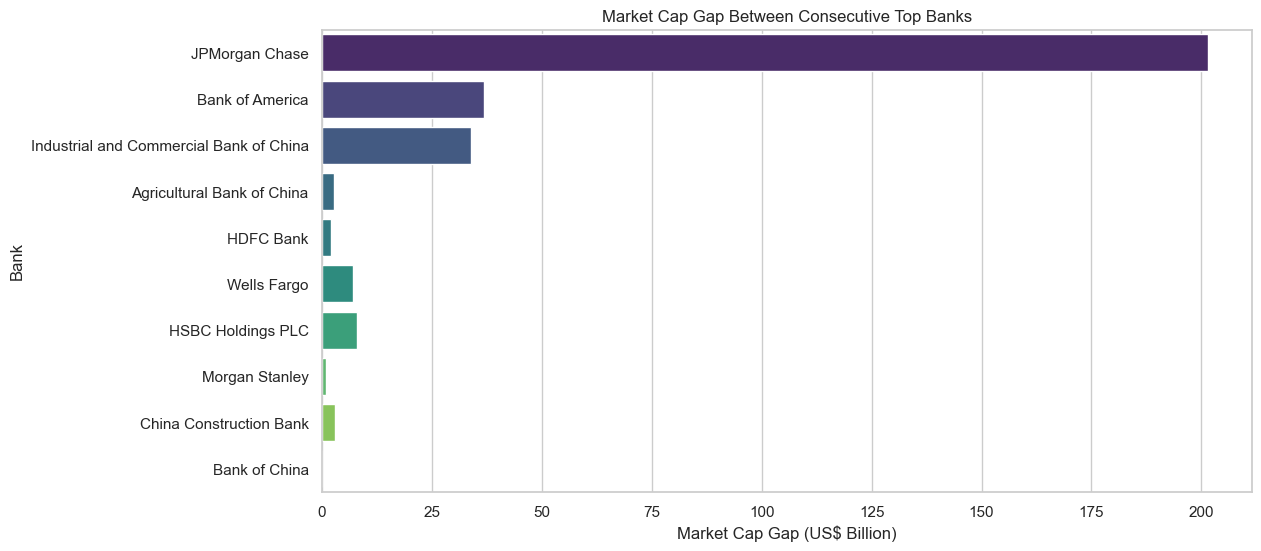

In [305]:
# Growth and Gap Analysis

#  Sort banks by market cap descending
df_sorted = df_clean.sort_values(by='market_cap_us_billion', ascending=False).reset_index(drop=True)

#  Compute the gap between consecutive banks
df_sorted['market_cap_gap'] = df_sorted['market_cap_us_billion'].diff(-1).fillna(0)  # Difference with next bank

#  Show top rows to analyze gaps
print(df_sorted[['bank_name', 'market_cap_us_billion', 'market_cap_gap', 'market_share_pct']].head(10))

#  Plot the market cap gaps
plt.figure(figsize=(12,6))
sns.barplot(x='market_cap_gap', y='bank_name', data=df_sorted.head(10), palette='viridis')
plt.xlabel('Market Cap Gap (US$ Billion)')
plt.ylabel('Bank')
plt.title('Market Cap Gap Between Consecutive Top Banks')
plt.show()


##**4.6. Market Dominance Analysis** <font color = red>[6 marks]</font> <br>

Q: Assess Market Dominance by Measuring Cumulative Share and Dominance Score

                                 bank_name  market_cap_us_billion  \
0                           JPMorgan Chase                 432.92   
1                          Bank of America                 231.52   
2  Industrial and Commercial Bank of China                 194.56   
3               Agricultural Bank of China                 160.68   
4                                HDFC Bank                 157.91   
5                              Wells Fargo                 155.87   
6                        HSBC Holdings PLC                 148.90   
7                           Morgan Stanley                 140.83   
8                  China Construction Bank                 139.82   
9                            Bank of China                 136.81   

   market_share_pct  cumulative_share_pct  dominance_score  
0         22.787422             22.787422        22.787422  
1         12.186418             34.973840        23.580129  
2         10.240970             45.214810        27.72789

C:\Users\hp\AppData\Local\Temp\ipykernel_25400\2620408066.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='cumulative_share_pct', y='bank_name', data=df_sorted.head(10), palette='viridis')


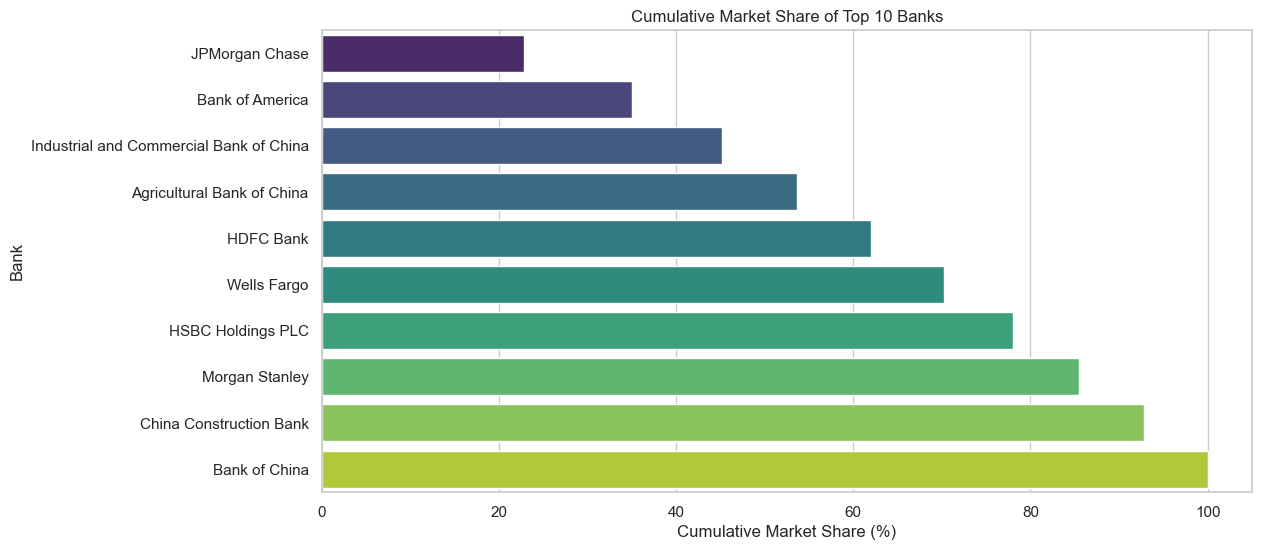

In [307]:
# Market Dominance Analysis
# Calculate cumulative market share
df_sorted['cumulative_share_pct'] = df_sorted['market_share_pct'].cumsum()

# Calculate a dominance score
# Example: dominance score = individual share + cumulative share weight
df_sorted['dominance_score'] = df_sorted['market_share_pct'] * 0.5 + df_sorted['cumulative_share_pct'] * 0.5

# Display top 10 banks with market dominance metrics
print(df_sorted[['bank_name', 'market_cap_us_billion', 'market_share_pct', 'cumulative_share_pct', 'dominance_score']].head(10))

# Plot cumulative market share
plt.figure(figsize=(12,6))
sns.barplot(x='cumulative_share_pct', y='bank_name', data=df_sorted.head(10), palette='viridis')
plt.xlabel('Cumulative Market Share (%)')
plt.ylabel('Bank')
plt.title('Cumulative Market Share of Top 10 Banks')
plt.show()


##**4.7. Segment-Wise Bank Analysis** <font color = red>[6 marks]</font> <br>

Q: Analyze Segment-Wise Bank Performance Based on Market Capitalization Ranges

In [317]:
# Segment Performance Analysis
# Check the actual min and max
print(df_clean[market_col].min(), df_clean[market_col].max())

# Define bins safely
bins = [0, 50, 100, 200, 500, df_clean[market_col].max() + 1]  # ensure last bin > max
labels = ['0-50', '50-100', '100-200', '200-500', f'>{int(bins[-2])}']

# Make sure bins are strictly increasing
bins = sorted(list(set(bins)))  # removes duplicates and sorts

# Create market cap range
df_clean['market_cap_range'] = pd.cut(df_clean[market_col], bins=bins, labels=labels, include_lowest=True)

# Group by range
segment_stats = df_clean.groupby('market_cap_range').agg(
    num_banks=('bank_name', 'count'),
    avg_market_cap=('market_cap_us_billion', 'mean'),
    total_market_cap=('market_cap_us_billion', 'sum')
).reset_index()

print(segment_stats)



136.81 432.92
  market_cap_range  num_banks  avg_market_cap  total_market_cap
0             0-50          0             NaN              0.00
1           50-100          0             NaN              0.00
2          100-200          8        154.4225           1235.38
3          200-500          2        332.2200            664.44
4             >500          0             NaN              0.00


C:\Users\hp\AppData\Local\Temp\ipykernel_25400\1274719013.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  segment_stats = df_clean.groupby('market_cap_range').agg(


##**4.8. Performance Dashboard** <font color = red>[6 marks]</font> <br>

Q: Generate a Comprehensive Performance Dashboard for Bank Rankings and Metrics

In [330]:
max_cap = df_clean['market_cap_us_billion'].max()

# Choose bins dynamically
if max_cap <= 500:
    bins = [0, 50, 100, 200, max_cap + 1]
    labels = ['0-50', '50-100', '100-200', f'200-{int(max_cap)}']
else:
    bins = [0, 50, 100, 200, 500, max_cap + 1]
    labels = ['0-50', '50-100', '100-200', '200-500', f'>{int(500)}']

df_clean['market_cap_range'] = pd.cut(
    df_clean['market_cap_us_billion'], 
    bins=bins, labels=labels, include_lowest=True
)

print(df_clean[['bank_name', 'market_cap_us_billion', 'market_cap_range']].head(10))


                                 bank_name  market_cap_us_billion  \
0                           JPMorgan Chase                 432.92   
1                          Bank of America                 231.52   
2  Industrial and Commercial Bank of China                 194.56   
3               Agricultural Bank of China                 160.68   
4                                HDFC Bank                 157.91   
5                              Wells Fargo                 155.87   
6                        HSBC Holdings PLC                 148.90   
7                           Morgan Stanley                 140.83   
8                  China Construction Bank                 139.82   
9                            Bank of China                 136.81   

  market_cap_range  
0          200-432  
1          200-432  
2          100-200  
3          100-200  
4          100-200  
5          100-200  
6          100-200  
7          100-200  
8          100-200  
9          100-200  


#5. Visualization Integration

In [332]:
# Visualization Setup Section

# 1. Prepare data for visualization platforms

# 2. Generate Tableau connection instructions

# 3. Generate Power BI connection instructions

# 4. Execute visualization setup
# 5. Sample Dashboard Layout (Documentation)
# Export cleaned and categorized data for visualization
df_clean.to_csv("bank_market_cap_analysis.csv", index=False)
df_clean.to_excel("bank_market_cap_analysis.xlsx", index=False)

print("Data exported successfully for Tableau and Power BI.")


Data exported successfully for Tableau and Power BI.
